In [1]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

print("CareFlow - Outpatient Activity Sequence Analysis")
print("Libraries loaded successfully!")


CareFlow - Outpatient Activity Sequence Analysis
Libraries loaded successfully!


In [2]:

file_path = Path("HospitalOPD-noname.csv")

if not file_path.exists():
    print("Dataset not found. Check that the CSV file is in the same folder as this notebook.")
else:
    df = pd.read_csv(file_path, low_memory=False)
    df = df.dropna(axis=1, how="all")

    print("Dataset loaded successfully!")
    print("Number of rows:", len(df))
    print("Number of columns:", len(df))

    print("\nColumn names:")
    for column in df.columns:
        print(column)


Dataset loaded successfully!
Number of rows: 62422
Number of columns: 62422

Column names:
record_no
patient_id
appointment_id
appointment_start_datetime
prescription_doctor_id
prescription_doctor_name
prescription_order_id
prescription_start_datetime
prescription_end_datetime
lab_id
lab_name
lab_start_datetime
lab_end_datetime
imaging_request_id
imaging_result_id
imaging_name
imaging_start_datetime
imaging_end_datetime
pharmacy_sale_line_id
medicine_name
pharmacy_start_datetime
pharmacy_end_datetime
flow_code
flow_name


In [3]:

# Find the appointment ID column
possible_ids = [
    col for col in df.columns
    if col.lower().strip() in [
        "appointment_id",
        "appointmentid",
        "appointment_no",
        "appointment_number"
    ]
]

if not possible_ids:
    possible_ids = [
        col for col in df.columns
        if "appointment" in col.lower() and "id" in col.lower()
    ]

if possible_ids:
    appointment_col = possible_ids[0]
    print("Appointment ID column:", appointment_col)
else:
    appointment_col = None
    print("Appointment ID column not found. Check the column names.")

# Identify activity start timestamps
activity_columns = {
    "Appointment Started": "appointment_start_datetime",
    "Prescription Started": "prescription_start_datetime",
    "Lab Started": "lab_start_datetime",
    "Imaging Started": "imaging_start_datetime",
    "Pharmacy Started": "pharmacy_start_datetime"
}

for activity, col in activity_columns.items():
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors="coerce")
        print(activity, "->", col)
    else:
        print("Column not found:", col)


Appointment ID column: appointment_id
Appointment Started -> appointment_start_datetime
Prescription Started -> prescription_start_datetime
Lab Started -> lab_start_datetime
Imaging Started -> imaging_start_datetime
Pharmacy Started -> pharmacy_start_datetime


In [4]:

# Stop if the appointment ID column was not identified
if appointment_col is None:
    raise ValueError("Appointment ID column not found. Check Step 4.")

# Keep only rows with an appointment ID
work_df = df[df[appointment_col].notna()].copy()

# Build one row per recorded activity
event_parts = []

for activity, timestamp_col in activity_columns.items():
    if timestamp_col not in work_df.columns:
        continue

    part = work_df[[appointment_col, timestamp_col]].copy()
    part = part.rename(columns={timestamp_col: "timestamp"})
    part["activity"] = activity
    part = part.dropna(subset=["timestamp"])

    event_parts.append(part)

if not event_parts:
    raise ValueError("No usable activity timestamps were found.")

events = pd.concat(event_parts, ignore_index=True)

# Remove exact duplicate event records only
events = events.drop_duplicates(
    subset=[appointment_col, "timestamp", "activity"]
)

# Sort each appointment's events chronologically
events = events.sort_values(
    [appointment_col, "timestamp", "activity"]
).reset_index(drop=True)

print("Event log created.")
print("Total events:", len(events))
print("Unique appointments:", events[appointment_col].nunique())
print("Activity types:", events["activity"].nunique())
print("\nEvents per activity:")
print(events["activity"].value_counts())


Event log created.
Total events: 112517
Unique appointments: 49912
Activity types: 5

Events per activity:
activity
Prescription Started    50536
Appointment Started     49912
Lab Started              6539
Imaging Started          5418
Pharmacy Started          112
Name: count, dtype: int64


In [5]:

# Create an ordered activity sequence for each appointment
sequence_df = (
    events.groupby(appointment_col, sort=False)["activity"]
    .agg(list)
    .reset_index(name="activity_sequence")
)

sequence_df["sequence_length"] = sequence_df["activity_sequence"].str.len()

# Create a readable pattern label
sequence_df["sequence_pattern"] = sequence_df["activity_sequence"].apply(
    lambda activities: " -> ".join(activities)
)

print("Appointment sequences created:", len(sequence_df))
print("\nSequence length summary:")
print(sequence_df["sequence_length"].describe())

print("\nExample sequences (appointment IDs hidden):")
for seq in sequence_df["activity_sequence"].head(5):
    print(" -> ".join(seq))


Appointment sequences created: 49912

Sequence length summary:
count    49912.000000
mean         2.254308
std          0.527140
min          1.000000
25%          2.000000
50%          2.000000
75%          2.000000
max          8.000000
Name: sequence_length, dtype: float64

Example sequences (appointment IDs hidden):
Appointment Started -> Prescription Started
Appointment Started -> Prescription Started
Appointment Started -> Prescription Started
Appointment Started -> Prescription Started
Appointment Started -> Prescription Started


In [6]:

total_appointments = len(sequence_df)

sequence_summary = (
    sequence_df["sequence_pattern"]
    .value_counts()
    .rename_axis("sequence_pattern")
    .reset_index(name="appointment_count")
)

sequence_summary["percentage_of_appointments"] = (
    sequence_summary["appointment_count"]
    / total_appointments * 100
).round(2)

# Show the 15 most frequent patterns
top_sequences = sequence_summary.head(15).copy()

print("Number of distinct sequence patterns:", len(sequence_summary))
display(top_sequences)


Number of distinct sequence patterns: 103


,sequence_pattern,appointment_count,percentage_of_appointments
0,Appointment Started -> Prescription Started,39203,78.54
1,Appointment Started -> Prescription Started ->...,4334,8.68
2,Appointment Started -> Prescription Started ->...,2217,4.44
3,Appointment Started -> Imaging Started -> Pres...,1216,2.44
4,Appointment Started -> Prescription Started ->...,555,1.11
5,Appointment Started -> Prescription Started ->...,430,0.86
6,Appointment Started -> Prescription Started ->...,396,0.79
7,Appointment Started -> Imaging Started -> Pres...,288,0.58
8,Appointment Started -> Lab Started -> Prescrip...,260,0.52
9,Imaging Started -> Appointment Started -> Pres...,222,0.44


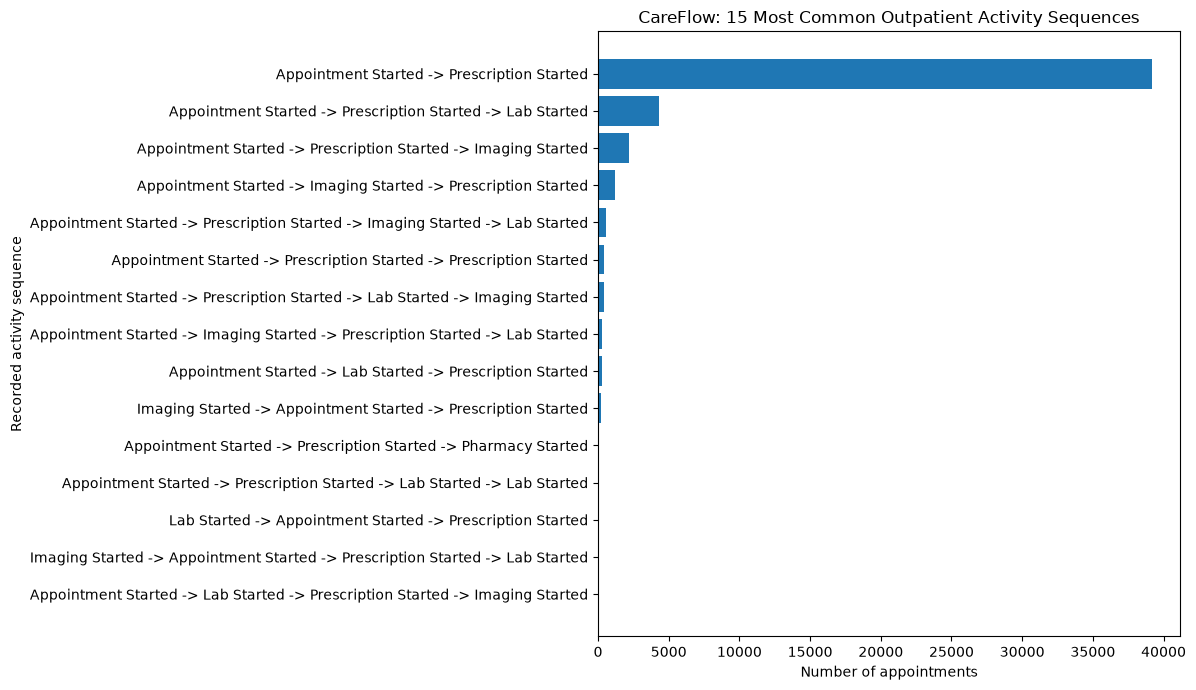

Chart saved: careflow_top_activity_sequences.png


In [7]:

plot_data = top_sequences.sort_values("appointment_count", ascending=True)

plt.figure(figsize=(12, 7))
plt.barh(
    plot_data["sequence_pattern"],
    plot_data["appointment_count"]
)
plt.xlabel("Number of appointments")
plt.ylabel("Recorded activity sequence")
plt.title("CareFlow: 15 Most Common Outpatient Activity Sequences")
plt.tight_layout()

plt.savefig("careflow_top_activity_sequences.png", dpi=200, bbox_inches="tight")
plt.show()

print("Chart saved: careflow_top_activity_sequences.png")


,sequence_length,appointment_count,percentage_of_appointments
0,1,11,0.02
1,2,39207,78.55
2,3,8841,17.71
3,4,1716,3.44
4,5,120,0.24
5,6,15,0.03
6,7,1,0.00
7,8,1,0.00


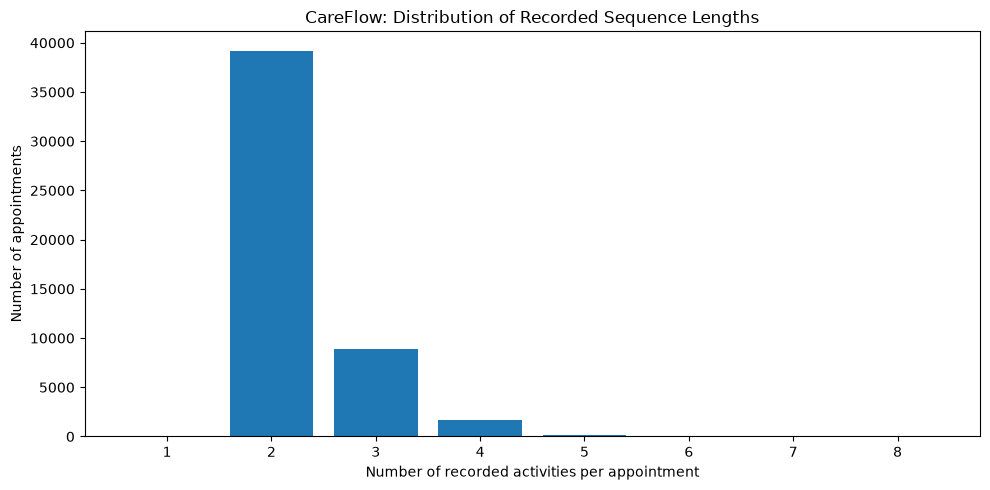

Chart saved: careflow_sequence_length_distribution.png


In [8]:

length_summary = (
    sequence_df["sequence_length"]
    .value_counts()
    .sort_index()
    .rename_axis("sequence_length")
    .reset_index(name="appointment_count")
)

length_summary["percentage_of_appointments"] = (
    length_summary["appointment_count"]
    / total_appointments * 100
).round(2)

display(length_summary.head(20))

plt.figure(figsize=(10, 5))
plt.bar(
    length_summary["sequence_length"],
    length_summary["appointment_count"]
)
plt.xlabel("Number of recorded activities per appointment")
plt.ylabel("Number of appointments")
plt.title("CareFlow: Distribution of Recorded Sequence Lengths")
plt.tight_layout()

plt.savefig("careflow_sequence_length_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

print("Chart saved: careflow_sequence_length_distribution.png")


In [9]:

from pathlib import Path

MIN_GROUP_SIZE = 10

# Export only patterns that meet the minimum group size
safe_sequences = sequence_summary[
    sequence_summary["appointment_count"] >= MIN_GROUP_SIZE
].copy()

# Export aggregate sequence counts
safe_sequences.to_csv(
    "careflow_activity_sequence_summary.csv",
    index=False
)

# Export aggregate sequence-length counts
length_summary.to_csv(
    "careflow_sequence_length_summary.csv",
    index=False
)

# Export a compact project summary
project_summary = pd.DataFrame([
    {
        "metric": "Appointments with recorded events",
        "value": total_appointments
    },
    {
        "metric": "Total recorded events",
        "value": len(events)
    },
    {
        "metric": "Distinct activity sequence patterns",
        "value": len(sequence_summary)
    },
    {
        "metric": "Sequence patterns meeting minimum group size",
        "value": len(safe_sequences)
    },
    {
        "metric": "Minimum group size for exported sequences",
        "value": MIN_GROUP_SIZE
    }
])

project_summary.to_csv(
    "careflow_sequence_analysis_summary.csv",
    index=False
)

print("Aggregate summary files created:")
for filename in [
    "careflow_activity_sequence_summary.csv",
    "careflow_sequence_length_summary.csv",
    "careflow_sequence_analysis_summary.csv",
    "careflow_top_activity_sequences.png",
    "careflow_sequence_length_distribution.png"
]:
    path = Path(filename)
    print(filename, "-", "created" if path.exists() else "missing")


Aggregate summary files created:
careflow_activity_sequence_summary.csv - created
careflow_sequence_length_summary.csv - created
careflow_sequence_analysis_summary.csv - created
careflow_top_activity_sequences.png - created
careflow_sequence_length_distribution.png - created


In [10]:

report_lines = [
    "CareFlow - Day 8 Outpatient Activity Sequence Analysis",
    "",
    f"Appointments with recorded events: {total_appointments}",
    f"Total recorded events: {len(events)}",
    f"Distinct sequence patterns: {len(sequence_summary)}",
    "",
    "Top 5 sequence patterns meeting the minimum group size:",
]

for _, row in safe_sequences.head(5).iterrows():
    report_lines.append(
        f"- {row['sequence_pattern']}: "
        f"{row['appointment_count']} appointments "
        f"({row['percentage_of_appointments']}%)"
    )

report_lines += [
    "",
    "Limitations:",
    "- Sequences reflect available timestamps, not necessarily every clinical activity.",
    "- Equal timestamps may not establish the true order of activities.",
    "- Longer sequences do not automatically indicate longer or worse care.",
    "- Small groups are excluded from the sequence summary export."
]

Path("careflow_day8_insights.txt").write_text(
    "\n".join(report_lines),
    encoding="utf-8"
)

print("Report created: careflow_day8_insights.txt")
print("\n".join(report_lines))


Report created: careflow_day8_insights.txt
CareFlow - Day 8 Outpatient Activity Sequence Analysis

Appointments with recorded events: 49912
Total recorded events: 112517
Distinct sequence patterns: 103

Top 5 sequence patterns meeting the minimum group size:
- Appointment Started -> Prescription Started: 39203 appointments (78.54%)
- Appointment Started -> Prescription Started -> Lab Started: 4334 appointments (8.68%)
- Appointment Started -> Prescription Started -> Imaging Started: 2217 appointments (4.44%)
- Appointment Started -> Imaging Started -> Prescription Started: 1216 appointments (2.44%)
- Appointment Started -> Prescription Started -> Imaging Started -> Lab Started: 555 appointments (1.11%)

Limitations:
- Sequences reflect available timestamps, not necessarily every clinical activity.
- Equal timestamps may not establish the true order of activities.
- Longer sequences do not automatically indicate longer or worse care.
- Small groups are excluded from the sequence summary